Давайте подивимося, як LSTM можна використовувати для побудови нейронної мережі прогнозування часових.

Будемо працювати з задачею прогнозування кількості пасажирів міжнародних авіаліній. З цим набором даних ми вже працювали в лекції "Time Series Analysis" і ви зможете порівняти результати :)

Задача полягає в тому, щоб за заданими роком і місяцем передбачити кількість пасажирів міжнародних авіаліній в одиницях виміру 1,000. Дані охоплюють період з січня 1949 року по грудень 1960 року, тобто 12 років, зі 144 спостереженнями.

Це регресійна задача. Тобто, знаючи кількість пасажирів (в тисячах) за останні місяці, можна передбачити, якою буде кількість пасажирів у наступному місяці. Набір даних має лише одну характеристику: "Кількість пасажирів" - `Passengers`.

Далі вже наведений код для читання даних, але нам їх ще треба буде трошки обробити.

In [19]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

# Завантаження даних
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)
df.set_index('Month', inplace=True)
display(df.head())

,Passengers
Month,
1949-01,112
1949-02,118
1949-03,132
1949-04,129
1949-05,121


**Завдання 1.** Створіть змінну типу `numpy.ndarray`, яка містить значення кількості пасажирів в форматі `float32`. Такий формат даних нам треба для тренування нейромережі.

In [20]:
import numpy as np

timeseries = np.array(df['Passengers'], dtype=np.float32)

print(type(timeseries))
print(timeseries.dtype)
print(timeseries.shape)
timeseries[:5]

<class 'numpy.ndarray'>
float32
(144,)


array([112., 118., 132., 129., 121.], dtype=float32)

Очікуваний результат:
```array([112., 118., 132., 129., 121.], dtype=float32)```

**Завдання 2**. Розбийте дані на тренувальні і валідаційні у співвідношенні 67% йде у тренування, 33 - у валідацію. Памʼятаємо, що ми працюємо з tim series, відповідно, навчаємось на давніших, валідуємось - на новіших.

In [21]:
train_size = int(len(timeseries)*0.67)

train = timeseries[:train_size]
val = timeseries[train_size:]

In [22]:
val.shape

(48,)

**Завдання 3**.

Реалізуйте функцію `create_dataset`, яка перетворить одномірний часовий ряд (набір даних) у формат, придатний для тренування нейромережі.

Функція повинна приймати два аргументи:
- `dataset` — numpy-масив часового ряду,
- `lookback` — кількість попередніх кроків, які використовуватимуться для передбачення.

Функція повинна повернути два **тензори** PyTorch:
- `X` — набір ознак (вікно попередніх значень),
- `y` — цільові значення (наступні після вікна кроки).

Дані ми будемо подавати моделі в наступному форматі:
`
tensor([[112.],
        [118.],
        [132.],
        [129.],
        [121.]])
`
Відповідно першою розмірністю буде йти розмір вхідного батча, а другою - розмір вхіднизх даних і в нас це 1, бо лише одне значення на вході щоразу.

Після виконання завдання запустіть код нижче. Ми будемо передбачати на основі кількості пасажирів в попередній день кількість пасажирів в наступний, тому `lookback == 1`.

Наскільки зрозуміла із завдання, передбачити потрібно наступний крок на основі попередніх, тобто змістити вікно на 1 значення

In [23]:
import torch

def create_dataset(dataset, lookback):
  X = []
  y = []
  for i in range(len(dataset)-lookback):
    feature = dataset[i: i + lookback]
    target = dataset[i + 1: i + lookback + 1]
    X.append(feature)
    y.append(target)
  return torch.tensor(X), torch.tensor(y)

In [24]:
lookback = 1
X_train, y_train = create_dataset(train, lookback=lookback)
X_val, y_val = create_dataset(val, lookback=lookback)
print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)

torch.Size([95, 1]) torch.Size([95, 1])
torch.Size([47, 1]) torch.Size([47, 1])


/tmp/ipykernel_1236/1963241730.py:11: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  return torch.tensor(X), torch.tensor(y)


Очікуваний результат:
```
torch.Size([95, 1]) torch.Size([95, 1])
torch.Size([47, 1]) torch.Size([47, 1])
```

**Завдання 4**.

Зверніть увагу на розмірності в попередньому завданні. Ми
З допомогою модуля `torch.nn` опишіть клас `AirModel`, який є нейронною мережею для прогнозування кількості пасажирів за допомогою LSTM.

1. **Конструктор класу** повинен приймати параметри `hidden_size`, `num_layers` та ініціювати шари:
   - LSTM-шар з наступними параметрами:
     - `input_size` — кожна точка часового ряду є окремим входом,,
     - `hidden_size` — заданий в конструкторі класу мережі,
     - `num_layers=1` — кількість шарів LSTM, задана в конструкторі мережі,
     - `batch_first=True` — визначає, що першим виміром є розмір батчу.
   - Лінійний шар (`nn.Linear`) для перетворення виходу LSTM на прогноз однієї точки.

2. **Метод forward** повинен виконувати наступні дії:
   - Передати вхідний тензор через LSTM-шар і отримати виходи (ігноруючи приховані стани).
   - Пропустити вихід LSTM через лінійний шар для отримання остаточного прогнозу.

Створіть об'єкт класу `AirModel` зі значеннями параметрів `hidden_size=50`, `num_layers=1` і протестуйте роботу моделі на вхідному тензорі `tensor([[112.]])`. На цьому етапі ми маємо переконатись, що модель здатна генерувати передбачення з рандомно ініційованими вагами.

In [14]:
import torch
import torch.nn as nn

class AirModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()
        self.lstm = nn.LSTM(input_size = input_size, # скільки чисел надходить на кожному кроці
                            hidden_size=hidden_size, # скільки чисел містить прихований шар
                            num_layers=num_layers, # скільки LSTM шарів використовуємо
                            batch_first=True) # перший вимір вхідного тензора відповідає кількості прикладів у батчі
        self.linear = nn.Linear(hidden_size, 1) # ініціюємо лінійний шар, який перетворить output прихованого шару в одне число

    def forward(self, x):
        x, _ = self.lstm(x) # отримуємо output від LSTM
        x = self.linear(x) # використовуємо лінійний шар для отримання одного числа - прогнозу
        return x

In [48]:
model = AirModel(input_size = 1, hidden_size = 50, num_layers = 1)
model

AirModel(
  (lstm): LSTM(1, 50, batch_first=True)
  (linear): Linear(in_features=50, out_features=1, bias=True)
)

In [16]:
x = torch.tensor([[112.]], dtype=torch.float32)
x = x.unsqueeze(-1)
x

tensor([[[112.]]])

In [17]:
model.eval()
with torch.no_grad():
  y = model(x)

In [18]:
print(x.shape, y.shape)
print(y)

torch.Size([1, 1, 1]) torch.Size([1, 1, 1])
tensor([[[0.4000]]])


Бачимо, що модель згенерувала число на основі рандомних вагів, як і очікувалося

**Завдання 5**.

Створіть об'єкт DataLoader для завантаження даних, використовуючи тренувальні вибірки `X_train` та `y_train`. Ваш DataLoader повинен виконувати наступні вимоги:

1. Використовувати клас `TensorDataset`, щоб об'єднати тензори ознак `X_train` і цільових значень `y_train`.
2. Дані повинні завантажуватися невеликими батчами розміром 8 за допомогою параметра `batch_size`.
3. Використовувати параметр `shuffle=True`, щоб дані перемішувалися перед кожною епохою тренування.


In [25]:
# Імпортуємо tensor dataset & data loader
from torch.utils.data import TensorDataset, DataLoader

In [26]:
train_ds = TensorDataset(X_train, y_train)
train_ds[0:5]

(tensor([[112.],
         [118.],
         [132.],
         [129.],
         [121.]]),
 tensor([[118.],
         [132.],
         [129.],
         [121.],
         [135.]]))

Бачимо, що правильно передається пара попередній-наступний крок

In [27]:
batch_size = 8
train_dl = DataLoader(train_ds, batch_size, shuffle=True)

In [30]:
next(iter(train_dl))

[tensor([[140.],
         [193.],
         [317.],
         [180.],
         [312.],
         [162.],
         [318.],
         [172.]]),
 tensor([[145.],
         [181.],
         [313.],
         [193.],
         [274.],
         [146.],
         [374.],
         [178.]])]

**Завдання 6**.

1. Реалізуйте навчання нейронної мережі `AirModel` для прогнозування часових рядів, використовуючи Adam-оптимізатор та функцію втрат MSE (середньоквадратичну похибку).
2. Створіть цикл тренування для 2000 епох, у якому на кожній епосі:
   - Виконуйте крок тренування моделі (прямий прохід, обчислення похибки, зворотний прохід і оновлення ваг).
   - Підраховуйте середню похибку на кожному батчі даних і зберігайте її у списку `losses`.
3. Раз на 100 епох проводьте валідацію моделі:
   - Перевіряйте модель на тренувальних та тестових даних без оновлення ваг.
   - Обчислюйте корінь середньоквадратичної похибки (RMSE) для тренувальної та тестової вибірок і виводьте результати на екран.
   
**Примітка:**
- Використовуйте вже створений `DataLoader` для отримання батчів даних.
- Валідацію виконуйте в режимі `eval()`, вимикаючи обчислення градієнтів з `torch.no_grad()`.

**Приклад виходу:**
```
Epoch 0: train RMSE 12.3456, test RMSE 15.6789
Epoch 100: train RMSE 9.8765, test RMSE 12.3456
...
```

In [31]:
X_train.ndim

2

In [32]:
def fit_air_model(model, loader, X_train, y_train, X_test, y_test, optimizer, criterion, epochs, log_every):
  if X_train.ndim == 2:
    X_train = X_train.unsqueeze(-1)
    y_train = y_train.unsqueeze(-1)
    X_test = X_test.unsqueeze(-1)
    y_test = y_test.unsqueeze(-1)

  losses = []
  for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0

    for xb, yb in loader:
      optimizer.zero_grad()
      pred = model(xb)
      loss = criterion(pred, yb)
      loss.backward()
      optimizer.step()
      epoch_loss += loss.item()

    losses.append(epoch_loss/len(loader))

    if epoch % log_every == 0:
      model.eval()
      with torch.no_grad():
        train_rmse = torch.sqrt(criterion(model(X_train), y_train)).item()
        test_rmse = torch.sqrt(criterion(model(X_test), y_test)).item()
      print(f"Epoch {epoch}: train RMSE {train_rmse:.4f}, test RMSE {test_rmse:.4f}")

  return losses

In [52]:
loader = train_dl
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr = 0.01)
epochs = 2000
log_every = 100

In [53]:
losses = fit_air_model(model, loader, X_train, y_train, X_val, y_val, optimizer, criterion, epochs, log_every)

Epoch 0: train RMSE 223.4622, test RMSE 419.7854
Epoch 100: train RMSE 77.0149, test RMSE 242.8546
Epoch 200: train RMSE 71.2730, test RMSE 219.0309
Epoch 300: train RMSE 71.8315, test RMSE 205.9098
Epoch 400: train RMSE 72.7736, test RMSE 200.9062
Epoch 500: train RMSE 76.0461, test RMSE 190.2863
Epoch 600: train RMSE 75.7385, test RMSE 190.9183
Epoch 700: train RMSE 74.5429, test RMSE 194.5067
Epoch 800: train RMSE 76.2196, test RMSE 189.8411
Epoch 900: train RMSE 76.9814, test RMSE 187.3168
Epoch 1000: train RMSE 75.4079, test RMSE 191.9928
Epoch 1100: train RMSE 75.1654, test RMSE 192.6725
Epoch 1200: train RMSE 75.2673, test RMSE 192.3847
Epoch 1300: train RMSE 74.8959, test RMSE 193.4505
Epoch 1400: train RMSE 75.3429, test RMSE 192.1730
Epoch 1500: train RMSE 75.9583, test RMSE 190.5149
Epoch 1600: train RMSE 75.8505, test RMSE 190.7978
Epoch 1700: train RMSE 74.6356, test RMSE 194.2279
Epoch 1800: train RMSE 75.7007, test RMSE 191.1963
Epoch 1900: train RMSE 75.8761, test RMSE 

**Завдання 7.** Побудуйте графік лосів. Зробіть висновок з графіку, чи навчилась модель?

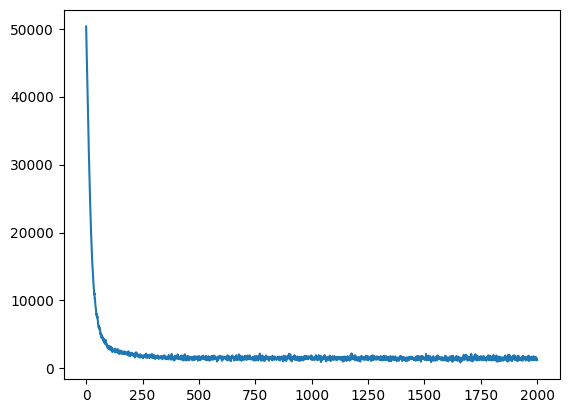

In [54]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

plt.plot(losses)

Модель навчилась, але не факт, що точно)

Доволі неочікувано, що середньоквадратичне відхилення тестового набору даних буде на порядок більшим за одиниці в нашому наборі даних. Середньоквадратичне відхилення 100 означає, що прогноз і фактичне значення будуть відрізнятися в середньому на 100 (тобто, 100 000 пасажирів у цьому наборі даних).



Щоб краще зрозуміти якість прогнозу, ви можете побудувати графік з кодом нижче (а ще нижче - описано, що відбувається в цьому коді, бо це теж корисно зрозуміти):

In [55]:
def plot_predicts(model):
  with torch.no_grad():
      # Зсув прогнозів для тренувальних даних
      train_plot = np.ones_like(timeseries) * np.nan
      y_pred = model(X_train)
      y_pred = y_pred[:, -1]
      train_plot[lookback:train_size] = model(X_train)[:, -1]

      # Зсув прогнозів для тестових даних
      test_plot = np.ones_like(timeseries) * np.nan
      test_plot[train_size+lookback:len(timeseries)] = model(X_val)[:, -1]

  # Візуалізація результатів
  plt.plot(timeseries, c='b')  # Реальні дані
  plt.plot(train_plot, c='r')  # Прогнози на тренувальних даних
  plt.plot(test_plot, c='g')   # Прогнози на тестових даних
  plt.show()

/tmp/ipykernel_1236/1527582659.py:7: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  train_plot[lookback:train_size] = model(X_train)[:, -1]
/tmp/ipykernel_1236/1527582659.py:11: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  test_plot[train_size+lookback:len(timeseries)] = model(X_val)[:, -1]


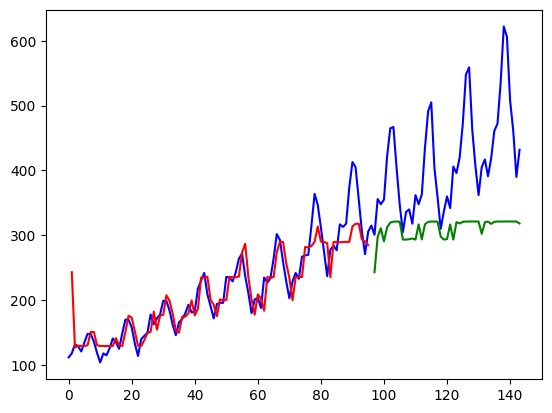

In [56]:
plot_predicts(model)

**Що відбувається в коді вище.** В цьому коді здійснюється процес прогнозування часових рядів за допомогою LSTM моделі, а також виведення графіку, який показує реальні значення, тренувальні та тестові прогнози. Ось що відбувається на кожному етапі:

1. **`torch.no_grad()`**: Цей контекстний менеджер вимикає обчислення градієнтів, що означає, що під час прогнозування не будуть зберігатися проміжні обчислення для зворотного проходу (backpropagation). Це підвищує ефективність під час прогнозування і зменшує використання пам'яті.

2. **Зсув прогнозів для тренувальних даних:**
   - Створюється масив `train_plot`, який має такий самий розмір, як і часовий ряд (`timeseries`), і заповнюється значеннями NaN (`np.nan`), щоб залишити місце для реальних значень.
   - Модель передбачає виходи для тренувальних даних `X_train`.
   - Використовується лише останнє передбачене значення для кожного входу LSTM (`y_pred[:, -1]`).
   - Прогнози зсуваються, починаючи з індексу `lookback` до кінця тренувальних даних (індекс `train_size`). Цей зсув потрібен, щоб зробити прогноз на основі попередніх даних і відобразити його на правильній частині графіку.

3. **Зсув прогнозів для тестових даних:**
   - Створюється масив `test_plot`, який також заповнюється NaN.
   - Прогнози для тестових даних додаються з індексу `train_size + lookback` до кінця реальних даних, щоб відобразити, де модель починає прогнозувати тестову вибірку.

4. **Побудова графіка:**
   - `plt.plot(timeseries, c='b')`: Виводить реальні значення часового ряду (синя лінія).
   - `plt.plot(train_plot, c='r')`: Виводить тренувальні прогнози (червона лінія).
   - `plt.plot(test_plot, c='g')`: Виводить тестові прогнози (зелена лінія).

**Чому це робиться:**
- Зсув прогнозів для тренувальних і тестових даних дозволяє візуально зрівняти, наскільки добре модель прогнозує як на тренувальній, так і на тестовій вибірках. Зазвичай, червона лінія (тренувальні прогнози) повинна точно відповідати синій лінії (реальні дані), а зелена лінія (тестові прогнози) дає змогу побачити, наскільки модель добре працює на нових даних, яких вона раніше не бачила.

**Завдання 8**. Навчіть модель з hidden_size=100 та порівняйте результати прогнозів з попередніми.

In [44]:
model_hs_100 = AirModel(input_size = 1, hidden_size = 100, num_layers = 1)
model_hs_100

AirModel(
  (lstm): LSTM(1, 100, batch_first=True)
  (linear): Linear(in_features=100, out_features=1, bias=True)
)

In [45]:
loader_hs_100 = train_dl
criterion_hs_100 = nn.MSELoss()
optimizer_hs_100 = torch.optim.Adam(model_hs_100.parameters(), lr = 0.01)
epochs = 2000
log_every = 100

In [47]:
losses_hs_100 = fit_air_model(model_hs_100, loader_hs_100, X_train, y_train, X_val, y_val, optimizer_hs_100, criterion_hs_100, epochs, log_every)

Epoch 0: train RMSE 220.2591, test RMSE 416.4426
Epoch 100: train RMSE 71.2513, test RMSE 218.7197
Epoch 200: train RMSE 73.3738, test RMSE 198.3526
Epoch 300: train RMSE 74.6248, test RMSE 194.2624
Epoch 400: train RMSE 75.5088, test RMSE 191.7159
Epoch 500: train RMSE 77.3674, test RMSE 187.0549
Epoch 600: train RMSE 78.3581, test RMSE 184.8293
Epoch 700: train RMSE 77.4049, test RMSE 186.9653
Epoch 800: train RMSE 74.7194, test RMSE 193.9753
Epoch 900: train RMSE 76.1643, test RMSE 189.9824
Epoch 1000: train RMSE 74.0323, test RMSE 196.1441
Epoch 1100: train RMSE 74.8084, test RMSE 193.7092
Epoch 1200: train RMSE 74.9458, test RMSE 193.3047
Epoch 1300: train RMSE 75.6745, test RMSE 191.2663
Epoch 1400: train RMSE 74.3296, test RMSE 195.1774
Epoch 1500: train RMSE 74.1383, test RMSE 195.7928
Epoch 1600: train RMSE 72.9420, test RMSE 200.1840
Epoch 1700: train RMSE 74.0118, test RMSE 196.2120
Epoch 1800: train RMSE 72.7512, test RMSE 201.0048
Epoch 1900: train RMSE 73.7985, test RMSE 

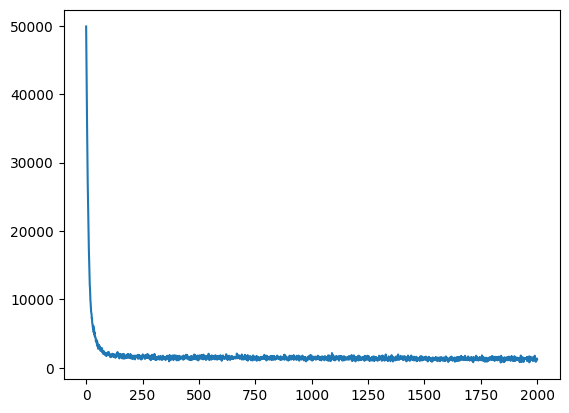

In [50]:
plt.plot(losses_hs_100)

/tmp/ipykernel_1236/1527582659.py:7: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  train_plot[lookback:train_size] = model(X_train)[:, -1]
/tmp/ipykernel_1236/1527582659.py:11: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments.
  test_plot[train_size+lookback:len(timeseries)] = model(X_val)[:, -1]


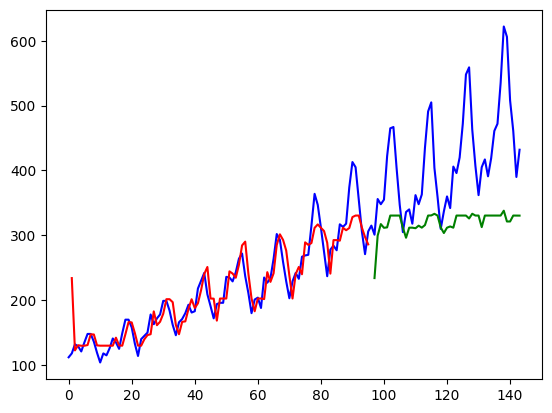

In [57]:
plot_predicts(model_hs_100)

Бачимо, що модель все ще дає великий розрив у значенні помилок на тренувальних та тестових даних. Порівняно з результатами моделі з прихованим шаром розміром 50, прихований шар 100 дає більший оверфіт на тренувальних даних.

Можливо, для покращення тренування моделі потрібно надавати більший контекст (lookback)

In [76]:
class AirModel_3(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()
        self.lstm = nn.LSTM(input_size = input_size, # скільки чисел надходить на кожному кроці
                            hidden_size=hidden_size, # скільки чисел містить прихований шар
                            num_layers=num_layers, # скільки LSTM шарів використовуємо
                            batch_first=True) # перший вимір вхідного тензора відповідає кількості прикладів у батчі
        self.linear = nn.Linear(hidden_size, 1) # ініціюємо лінійний шар, який перетворить output прихованого шару в одне число

    def forward(self, x):
        x, _ = self.lstm(x) # отримуємо output від LSTM
        x = x[:, -1, :] # Беремо лише останній часовий крок
        x = self.linear(x) # використовуємо лінійний шар для отримання одного числа - прогнозу
        return x

In [65]:
def create_dataset_3(data, lookback):
    X, y = [], []

    for i in range(len(data) - lookback):
        X.append(data[i:i + lookback])
        y.append(data[i + lookback])

    X = torch.tensor(X, dtype=torch.float32)
    y = torch.tensor(y, dtype=torch.float32).unsqueeze(-1)

    return X, y

In [66]:
lookback_3 = 3
X_train_3, y_train_3 = create_dataset_3(train, lookback=lookback_3)
X_val_3, y_val_3 = create_dataset_3(val, lookback=lookback_3)
print(X_train_3.shape, y_train_3.shape)
print(X_val_3.shape, y_val_3.shape)

torch.Size([93, 3]) torch.Size([93, 1])
torch.Size([45, 3]) torch.Size([45, 1])


In [77]:
model_3 = AirModel_3(input_size = 1, hidden_size = 50, num_layers = 1)

In [68]:
train_ds_3 = TensorDataset(X_train_3, y_train_3)
train_ds_3[0:5]

(tensor([[112., 118., 132.],
         [118., 132., 129.],
         [132., 129., 121.],
         [129., 121., 135.],
         [121., 135., 148.]]),
 tensor([[129.],
         [121.],
         [135.],
         [148.],
         [148.]]))

In [69]:
batch_size = 8
train_dl_3 = DataLoader(train_ds_3, batch_size, shuffle=True)

In [78]:
loader_3= train_dl_3
criterion_3 = nn.MSELoss()
optimizer_3 = torch.optim.Adam(model_3.parameters(), lr = 0.01)
epochs = 2000
log_every = 100

In [79]:
def fit_air_model_3(model, loader, X_train, y_train, X_test, y_test, optimizer, criterion, epochs, log_every):
  if X_train.ndim == 2:
    X_train = X_train.unsqueeze(-1)
    X_test = X_test.unsqueeze(-1)

  losses = []
  for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0

    for xb, yb in loader:
      xb = xb.unsqueeze(-1)
      optimizer.zero_grad()
      pred = model(xb)
      loss = criterion(pred, yb)
      loss.backward()
      optimizer.step()
      epoch_loss += loss.item()

    losses.append(epoch_loss/len(loader))

    if epoch % log_every == 0:
      model.eval()
      with torch.no_grad():
        train_rmse = torch.sqrt(criterion(model(X_train), y_train)).item()
        test_rmse = torch.sqrt(criterion(model(X_test), y_test)).item()
      print(f"Epoch {epoch}: train RMSE {train_rmse:.4f}, test RMSE {test_rmse:.4f}")

  return losses

In [80]:
losses_3 = fit_air_model_3(model_3, loader_3, X_train_3, y_train_3, X_val_3, y_val_3, optimizer_3, criterion_3, epochs, log_every)

Epoch 0: train RMSE 224.7338, test RMSE 423.1053
Epoch 100: train RMSE 49.8472, test RMSE 203.4906
Epoch 200: train RMSE 34.3082, test RMSE 157.0026
Epoch 300: train RMSE 30.9866, test RMSE 144.9131
Epoch 400: train RMSE 27.5431, test RMSE 128.2620
Epoch 500: train RMSE 27.5167, test RMSE 133.6399
Epoch 600: train RMSE 26.4630, test RMSE 126.6517
Epoch 700: train RMSE 25.3933, test RMSE 123.3681
Epoch 800: train RMSE 24.5403, test RMSE 110.1511
Epoch 900: train RMSE 24.3038, test RMSE 115.6916
Epoch 1000: train RMSE 24.4164, test RMSE 113.6227
Epoch 1100: train RMSE 23.1168, test RMSE 104.2910
Epoch 1200: train RMSE 23.2679, test RMSE 100.0878
Epoch 1300: train RMSE 21.4542, test RMSE 100.0100
Epoch 1400: train RMSE 22.7393, test RMSE 95.2985
Epoch 1500: train RMSE 24.8872, test RMSE 103.0363
Epoch 1600: train RMSE 23.6414, test RMSE 107.5185
Epoch 1700: train RMSE 24.6715, test RMSE 105.0021
Epoch 1800: train RMSE 24.2322, test RMSE 108.9708
Epoch 1900: train RMSE 27.5771, test RMSE 1

In [82]:
def plot_predicts_3(model, X_train, X_val, lookback):
    model.eval()

    with torch.no_grad():
        # LSTM очікує (samples, sequence_length, input_size)
        if X_train.ndim == 2:
            X_train = X_train.unsqueeze(-1)
            X_val = X_val.unsqueeze(-1)

        # Прогнози: одне значення на кожну послідовність
        train_preds = model(X_train).squeeze(-1).cpu().numpy()
        val_preds = model(X_val).squeeze(-1).cpu().numpy()

    # Масиви для відображення прогнозів на часовій шкалі
    train_plot = np.full(len(timeseries), np.nan)
    val_plot = np.full(len(timeseries), np.nan)

    # Прогнози починаються після lookback значень
    train_plot[lookback:train_size] = train_preds

    # Прогнози на валідаційній частині
    val_plot[train_size + lookback:len(timeseries)] = val_preds

    # Графік
    plt.figure(figsize=(12, 5))
    plt.plot(timeseries, c='b', label='Actual')
    plt.plot(train_plot, c='r', label='Train predictions')
    plt.plot(val_plot, c='g', label='Validation predictions')

    plt.legend()
    plt.show()

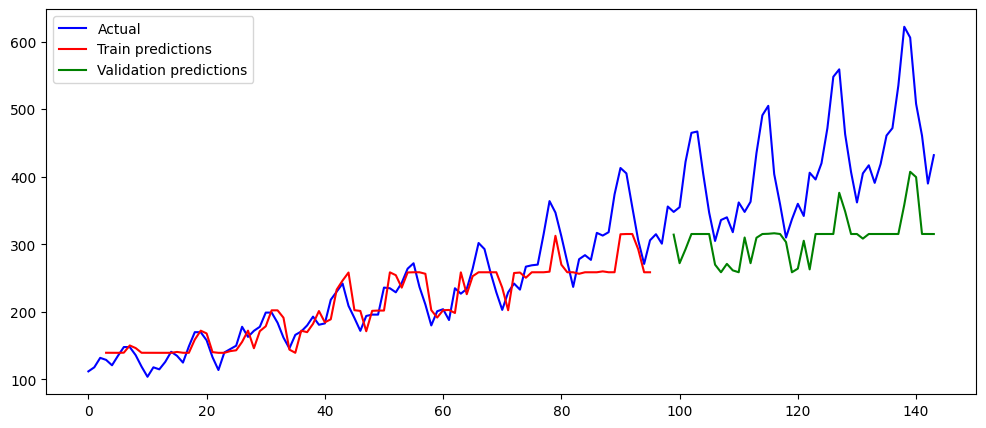

In [83]:
plot_predicts_3(model_3, X_train_3, X_val_3, lookback=3)

Бачимо, що на контексті 3-х попередніх днів також сильний оверфіт на тренувальних даних